Part 2

Get predictions on evaluation set

In [ ]:
import numpy as np
from scipy.special import softmax

pred_output = trainer.predict(eval_dataset)

logits = pred_output.predictions
labels = pred_output.label_ids

probs = softmax(logits, axis=1)[:, 1]

# Use your chosen threshold (0.3)
threshold = 0.3
preds = (probs >= threshold).astype(int)

Convert eval_dataset back to DataFrame

In [ ]:
eval_df = eval_dataset.to_pandas()

eval_df["label"] = labels
eval_df["pred"] = preds
eval_df["prob"] = probs

Create cohorts

In [ ]:
# High-black cohort
high_black = eval_df[eval_df["black"] >= 0.5]

# Reference cohort (white, not black)
reference = eval_df[(eval_df["black"] < 0.1) & (eval_df["white"] >= 0.5)]

print("High-black cohort size:", len(high_black))
print("Reference cohort size:", len(reference))

High-black cohort size: 170
Reference cohort size: 202


Define metric function

In [ ]:
from sklearn.metrics import confusion_matrix

def compute_metrics(df):
    y_true = df["label"]
    y_pred = df["pred"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    TPR = tp / (tp + fn) if (tp + fn) > 0 else 0
    FPR = fp / (fp + tn) if (fp + tn) > 0 else 0
    FNR = fn / (fn + tp) if (fn + tp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    return {
        "TPR": TPR,
        "FPR": FPR,
        "FNR": FNR,
        "Precision": precision,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

Compute metrics for both cohorts

In [ ]:
metrics_black = compute_metrics(high_black)
metrics_ref = compute_metrics(reference)

print("High-black metrics:", metrics_black)
print("Reference metrics:", metrics_ref)

High-black metrics: {'TPR': np.float64(0.6190476190476191), 'FPR': np.float64(0.08411214953271028), 'FNR': np.float64(0.38095238095238093), 'Precision': np.float64(0.8125), 'TN': np.int64(98), 'FP': np.int64(9), 'FN': np.int64(24), 'TP': np.int64(39)}
Reference metrics: {'TPR': np.float64(0.3508771929824561), 'FPR': np.float64(0.07586206896551724), 'FNR': np.float64(0.6491228070175439), 'Precision': np.float64(0.6451612903225806), 'TN': np.int64(134), 'FP': np.int64(11), 'FN': np.int64(37), 'TP': np.int64(20)}


Disparate Impact Ratio

In [ ]:
disparate_impact = metrics_black["FPR"] / metrics_ref["FPR"]

print("Disparate Impact (FPR ratio):", disparate_impact)

Disparate Impact (FPR ratio): 1.10875106202209


Summary Table

In [ ]:
import pandas as pd

summary = pd.DataFrame([
    ["High-Black", metrics_black["TPR"], metrics_black["FPR"], metrics_black["FNR"], metrics_black["Precision"]],
    ["Reference", metrics_ref["TPR"], metrics_ref["FPR"], metrics_ref["FNR"], metrics_ref["Precision"]],
], columns=["Group", "TPR", "FPR", "FNR", "Precision"])

print(summary)

        Group       TPR       FPR       FNR  Precision
0  High-Black  0.619048  0.084112  0.380952   0.812500
1   Reference  0.350877  0.075862  0.649123   0.645161


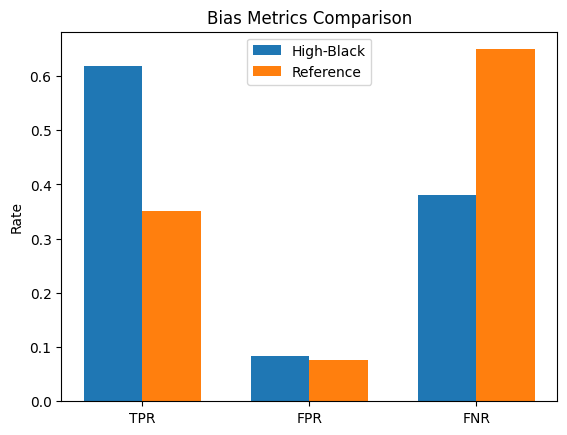

In [ ]:
import matplotlib.pyplot as plt

labels_plot = ["TPR", "FPR", "FNR"]

black_vals = [metrics_black["TPR"], metrics_black["FPR"], metrics_black["FNR"]]
ref_vals = [metrics_ref["TPR"], metrics_ref["FPR"], metrics_ref["FNR"]]

x = np.arange(len(labels_plot))
width = 0.35

plt.figure()
plt.bar(x - width/2, black_vals, width, label="High-Black")
plt.bar(x + width/2, ref_vals, width, label="Reference")

plt.xticks(x, labels_plot)
plt.ylabel("Rate")
plt.title("Bias Metrics Comparison")
plt.legend()
plt.show()

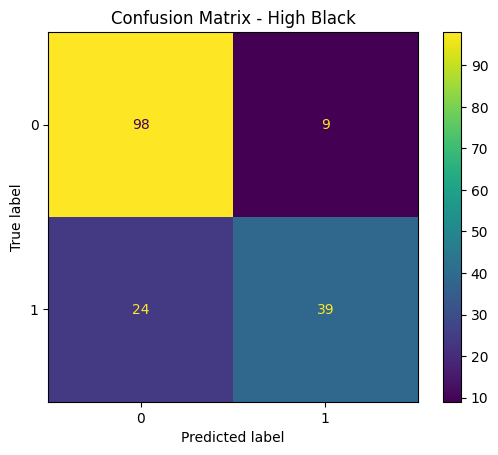

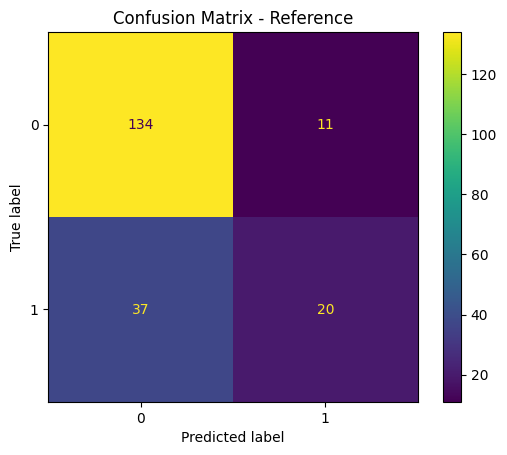

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# High-black
ConfusionMatrixDisplay.from_predictions(
    high_black["label"], high_black["pred"]
)
plt.title("Confusion Matrix - High Black")
plt.show()

# Reference
ConfusionMatrixDisplay.from_predictions(
    reference["label"], reference["pred"]
)
plt.title("Confusion Matrix - Reference")
plt.show()

In [ ]:
aif_df = eval_df[["label", "pred"]].copy()

# Create protected attribute (group)
aif_df["group"] = (eval_df["black"] >= 0.5).astype(int)


In [ ]:
!pip install aif360

In [ ]:
from aif360.datasets import BinaryLabelDataset

dataset = BinaryLabelDataset(
    df=aif_df,
    label_names=["label"],
    protected_attribute_names=["group"]
)

In [ ]:
pred_dataset = dataset.copy()
pred_dataset.labels = aif_df["pred"].values.reshape(-1, 1)

In [ ]:
from aif360.metrics import ClassificationMetric

metric = ClassificationMetric(
    dataset,
    pred_dataset,
    unprivileged_groups=[{"group": 1}],  # high-black
    privileged_groups=[{"group": 0}]     # others
)

print("Statistical Parity Difference:", metric.statistical_parity_difference())
print("Equal Opportunity Difference:", metric.equal_opportunity_difference())

pip install 'aif360[inFairness]'


Statistical Parity Difference: 0.22108213936103943
Equal Opportunity Difference: 0.0513392857142857


## Bias Analysis: Disparity Across Cohorts (Part 2)

### Which metric shows the largest disparity?

The largest disparity is observed in the **True Positive Rate (TPR)**:

| Metric | High-Black Cohort | Reference Cohort | Difference |
|--------|-------------------|------------------|------------|
| TPR    | 0.619             | 0.351            | **+0.268** |
| FPR    | 0.084             | 0.076            | +0.008     |
| FNR    | 0.381             | 0.649            | -0.268     |
| Precision | 0.813          | 0.645            | +0.168     |

The TPR difference of 0.268 is substantially larger than the FPR difference of 0.008.

### Does the model over-flag or under-flag the high-black cohort?

The model **over-flags AND over-detects** the high-black cohort relative to the reference cohort:

- **Over-flagging (FPR):** The high-black cohort has a slightly higher false positive rate (0.084 vs. 0.076), meaning non-toxic comments in this group are about 10% more likely to be incorrectly flagged as toxic. The disparate impact ratio (FPR ratio) is 1.109.

- **Over-detecting (TPR):** More notably, the model has a **much higher true positive rate** for the high-black cohort (0.619 vs. 0.351). It correctly identifies toxic comments in this group at nearly double the rate of the reference cohort.

- **Under-flagging (FNR):** The false negative rate is substantially lower for the high-black cohort (0.381 vs. 0.649), meaning the model misses fewer toxic comments in this group.

Thus, the model is **not under-flagging** the high-black cohort. Instead, it is more sensitive to both toxic and non-toxic content in this group, leading to higher detection of actual toxicity AND slightly higher false positives.

### Real-world consequences

**For users in the high-black cohort:**
- *Over-flagging consequences:* Non-toxic comments may be incorrectly removed, leading to frustration, perceived unfairness, and a chilling effect on speech about race or identity.
- *Over-detection consequences:* Toxic comments targeting this group are more likely to be caught, providing better protection against harassment.
- *Net effect:* Mixed—better protection from targeted harassment, but higher risk of unjustified censorship of legitimate speech.

**For users in the reference cohort:**
- *Lower detection consequences:* Toxic comments targeting or from this group are more likely to go undetected, creating a less safe environment.
- *Lower false positives:* Non-toxic comments are less likely to be wrongly flagged, providing a smoother user experience.
- *Net effect:* Better experience for non-toxic users, but worse protection from toxicity.

**For the platform:**
- *Legal/ethical risk:* The model treats identity-associated language differently. While the disparity is not extreme, the systematic difference in TPR (0.268) could raise fairness concerns.
- *Operational impact:* More toxic content is caught in the high-black cohort, reducing harm, but the disparate treatment may require justification under content moderation policies.
- *Reputational impact:* If discovered, the model's higher sensitivity to the high-black cohort could be perceived as either protective (catching more hate speech) or discriminatory (over-policing), depending on the narrative.